# YOLO training

Trains a YOLO11n detector on the team's 5-class dataset at two image sizes (640 and 960 px), tests both on the held-out test set, and compares them.

- **Why YOLO:** it draws a box around each problem and names it, so one photo can show several conditions.
- **Why fine-tune YOLO11n:** it starts from weights pretrained on COCO, so it already knows edges and shapes and needs less data and time than training from scratch. `n` (nano) is the smallest version, fast enough for the app.
- **Order:** Setup → Training → Testing and logging → Results → Comparing 640 and 960 → Where the model goes wrong.
- **Dataset checks** are in `01_eda.ipynb` (Part 2 covers this dataset).

# Setup

Every run uses the same `SETTINGS`, so the only thing that changes between runs is the image size:

- `epochs = 100`: my first 640 px run had 50 epochs and was still improving at the end (val mAP50 0.793), so I doubled it.
- `patience = 20`: stop early if validation mAP does not improve for 20 epochs in a row.
- `batch = 16`: 16 images per training step; fits in the 6 GB laptop GPU at 640 px.
- `seed = 0`: fixed randomness, so a run can be repeated.
- `workers = 3`: CPU processes that load images; changes speed only, not results.

In [1]:
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

REPO  = next(folder for folder in Path.cwd().parents if (folder / 'data' / 'raw').exists()) #loops up from dir to find folder/data/raw and returns it
DATA = REPO / "data" / "raw" / "oral_dataset" / "data.yaml"
RUNS = REPO / "models" / "yolo_caries" / "results" / "Junwei"
assert DATA.exists(), f"path not found: {DATA}"


#Settings

sizes = (640, 960)   # 960 was trained on Google Cloud (see the note under Training); the loop skips it because its best.pt exists

SETTINGS = dict(
    data= str(DATA),
    epochs = 100,
    patience = 20, #stops if no improvement
    batch = 16,
    workers = 3,
    seed=0,
    project = str(RUNS),
)

# Training the model

In [ ]:
for size in sizes:
    name = f"yolo11n_{size}_{SETTINGS['epochs']}ep"
    if (RUNS / name / "weights" / "best.pt").exists():
        print(name, "already trained, skipping")
        continue
    model = YOLO(str(REPO / "yolo11n.pt"))        # fresh pretrained weights for each size
    model.train(imgsz=size, name=name, **SETTINGS)

New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.11.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\angju\Documents\AI WIU DL project\Deep-Learning-WIU\data\raw\oral_dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, l

: 

**The 960 px run was trained on Google Cloud.** On my laptop one 960 px epoch took about 8 minutes, so 100 epochs would take about 14 hours. It ran on Colab Enterprise with 1 NVIDIA L4 GPU and 16 CPUs, using Ultralytics 8.4.215 (my laptop has 8.4.202). The settings were the same as `SETTINGS`, except `workers=12`: more CPUs to keep the GPU busy, which changes speed only.

```python
model = YOLO("yolo11n.pt")
model.train(data=".../oral_dataset/data.yaml", imgsz=960, epochs=100, patience=20, batch=16, workers=12, seed=0, name="yolo11n_960_100ep")
```

The run folder was copied to a storage bucket after every epoch, then downloaded into `results/Junwei/yolo11n_960_100ep/` (`results.csv`, `args.yaml`, `weights/best.pt`). Comparing the two runs' `args.yaml` files shows that only `imgsz`, `workers` and file paths differ.

# Testing and logging

`best.pt` is the epoch with the best **validation** score, so validation scores are optimistic. The test set was never used to choose anything, so it gives the fair score. Each model is tested twice, as the dataset README asks:

- on all test images (`data.yaml`)
- on only the test images labelled by people (`data_person.yaml`)

Each model is tested at the size it was trained at. One row per run goes to the team's `experiments.csv`. Runs already logged are skipped, so running this again does not add duplicate rows. (The output below is from the first run, before the skip was added.)

In [ ]:
# Test each finished run on the held-out test set, then log it to the team's experiments.csv
EXPERIMENTS = REPO / "models" / "yolo_caries" / "results" / "experiments.csv"
PERSON = DATA.with_name("data_person.yaml")   # same test split, only images labelled by people
logged = set(pd.read_csv(EXPERIMENTS).run_id)

rows = []
for size in sizes: #(640, 960)
    name = f"yolo11n_{size}_{SETTINGS['epochs']}ep" #yolo11n, size, number of epochs
    if f"Junwei_{name}" in logged:
        print(name, "already tested and logged, skipping")
        continue
    best = RUNS / name / "weights" / "best.pt" # best epoch
    model = YOLO(str(best)) #model
    test = model.val(data=str(DATA), split="test", imgsz=size, batch=16, project=str(RUNS), name=f"{name}_test") #test on test set
    person = model.val(data=str(PERSON), split="test", imgsz=size, batch=16, project=str(RUNS), name=f"{name}_test_person") #test on test set with the person labelled images split
    per_class = ", ".join(f"{model.names[c]} {test.box.ap50[i]:.3f}" for i, c in enumerate(test.box.ap_class_index)) #i is score, c is name, extracted from list of class numbers
    rows.append(dict(
        run_id=f"Junwei_{name}", date=pd.Timestamp.today().date(), member="Junwei", model="yolo11n",
        data_version="oral_dataset 2026-11-13", imgsz=size, epochs=SETTINGS["epochs"], batch=16, lr0=0.01,
        mAP50=round(test.box.map50, 4), mAP50_95=round(test.box.map, 4),
        precision=round(test.box.mp, 4), recall=round(test.box.mr, 4),
        
        weights_path=best.relative_to(REPO).as_posix(),
        notes=f"scores on data.yaml TEST; person-only test mAP50 {person.box.map50:.3f} mAP50-95 {person.box.map:.3f}; per-class test mAP50: {per_class}; seed=0",
    ))

if rows:
    pd.DataFrame(rows).to_csv(EXPERIMENTS, mode="a", header=False, index=False, lineterminator="\n")   # "\n" matches the file's existing line endings
    print(pd.DataFrame(rows)[["run_id", "mAP50", "mAP50_95", "precision", "recall"]])

# Results

My two runs as logged in `experiments.csv` (test set, 2,936 images).

In [2]:
EXPERIMENTS = REPO / "models" / "yolo_caries" / "results" / "experiments.csv"
my_runs = [f"Junwei_yolo11n_{size}_{SETTINGS['epochs']}ep" for size in sizes]
mine = pd.read_csv(EXPERIMENTS).set_index("run_id").loc[my_runs]

print(mine[["imgsz", "mAP50", "mAP50_95", "precision", "recall"]].T)
for run, note in mine.notes.items():          # notes hold the person-only and per-class scores
    print("\n" + run + ":\n  " + note.replace("; ", "\n  "))

run_id     Junwei_yolo11n_640_100ep  Junwei_yolo11n_960_100ep
imgsz                      640.0000                  960.0000
mAP50                        0.8139                    0.8112
mAP50_95                     0.4253                    0.4226
precision                    0.7834                    0.7924
recall                       0.7630                    0.7686

Junwei_yolo11n_640_100ep:
  scores on data.yaml TEST
  person-only test mAP50 0.815 mAP50-95 0.426
  per-class test mAP50: Calculus 0.628, Caries 0.806, Hypodontia 0.827, Mouth_Ulcer 0.916, Tooth_Discoloration 0.894
  seed=0

Junwei_yolo11n_960_100ep:
  scores on data.yaml TEST
  person-only test mAP50 0.812 mAP50-95 0.423
  per-class test mAP50: Calculus 0.640, Caries 0.810, Hypodontia 0.805, Mouth_Ulcer 0.911, Tooth_Discoloration 0.890
  seed=0


| Test set | 640 px | 960 px |
|---|---|---|
| mAP50 | **0.814** | 0.811 |
| mAP50-95 | **0.425** | 0.423 |
| Precision | 0.783 | **0.792** |
| Recall | 0.763 | **0.769** |
| mAP50, person-labelled test only | **0.815** | 0.812 |
| Calculus | 0.628 | **0.640** |
| Caries | 0.806 | **0.810** |
| Hypodontia | **0.827** | 0.805 |
| Mouth ulcer | **0.916** | 0.911 |
| Tooth discolouration | **0.894** | 0.890 |

**What the results mean:**

- **960 px does not beat 640 px.** On test it is 0.003 lower on mAP50; on validation it was 0.006 higher. With one run per size, gaps this small cannot be told apart from run-to-run variation, so I treat the two sizes as equal.
- **960 px helps a little only where boxes are small** (calculus +0.012, caries +0.004) and loses on hypodontia (−0.022). `01_eda.ipynb` section 9 explains why the gain is small: only 3.2% of boxes are under 32 px at 640 px.
- **Choice: 640 px.** The same accuracy, with 2.25× fewer pixels per image, so it is faster to train and to run in the app.
- **Test (0.814) is close to validation (0.808)**, so picking `best.pt` on validation did not over-fit to the validation set.
- **Precision 0.78 and recall 0.76** (at the confidence cut-off where they balance best): about 1 in 5 boxes is a false alarm, and about 1 in 4 real problems is missed. For a screening aid a missed problem is worse than a false alarm, so the app's cut-off should be chosen to raise recall.
- **Person-labelled test ≈ full test** (0.815 vs 0.814), so the Qwen-labelled test images do not change the result.
- **Limits:** one run per size; val/test hold copies of training photos (Aiden's finding), so these scores are optimistic; val/test are mostly Roboflow photos (`01_eda.ipynb` section 10).

## Comparing 640 and 960 during training

Validation mAP50 for every epoch of both runs, read from each run's `results.csv`, and the gap between them.

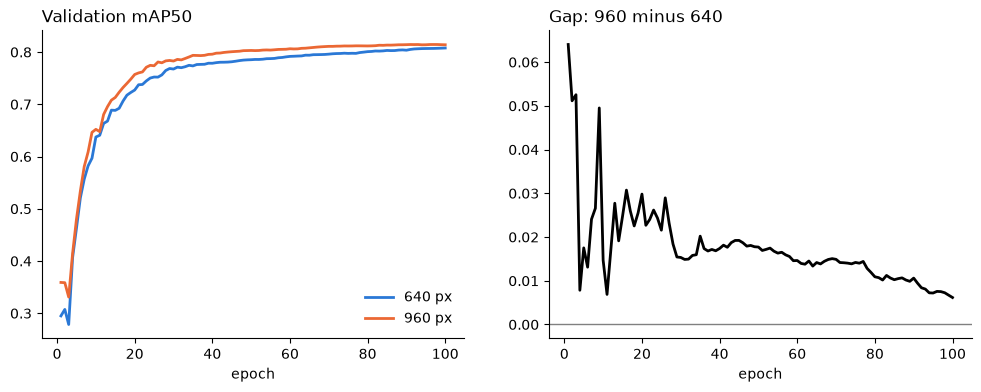

epoch 25: gap +0.022
epoch 50: gap +0.018
epoch 75: gap +0.014
epoch 100: gap +0.006


In [ ]:
import matplotlib.pyplot as plt

curves = {size: pd.read_csv(RUNS / f"yolo11n_{size}_{SETTINGS['epochs']}ep" / "results.csv") for size in sizes}
gap = curves[960]["metrics/mAP50(B)"] - curves[640]["metrics/mAP50(B)"]

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
for size, color in zip(sizes, ("#2a78d6", "#eb6834")):
    left.plot(curves[size].epoch, curves[size]["metrics/mAP50(B)"], color=color, linewidth=2, label=f"{size} px")
left.set_title("Validation mAP50", loc="left")
left.legend(frameon=False)
right.plot(curves[640].epoch, gap, color="black", linewidth=2)
right.axhline(0, color="grey", linewidth=1)
right.set_title("Gap: 960 minus 640", loc="left")
for ax in (left, right):
    ax.set_xlabel("epoch")
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

for epoch in (25, 50, 75, 100):
    print(f"epoch {epoch}: gap {gap[epoch - 1]:+.3f}")

**Finding:** 960 px learns faster early on (+0.022 at epoch 25), but the gap shrinks steadily to +0.006 by epoch 100. Bigger images mainly speed up learning; they do not raise where the model ends up. Both curves have almost levelled off: 640 px gained only 0.0015 over its last 7 epochs, and 960 px peaked at epoch 97. More epochs would add very little.

## Where the model goes wrong

The confusion matrix of the 640 px model on the test set (saved by the test cell). Each column is the true class and adds up to 1; each row is what the model predicted. `background` means no box: the bottom row is missed problems, and the right-hand column is boxes drawn where nothing was labelled (false alarms).

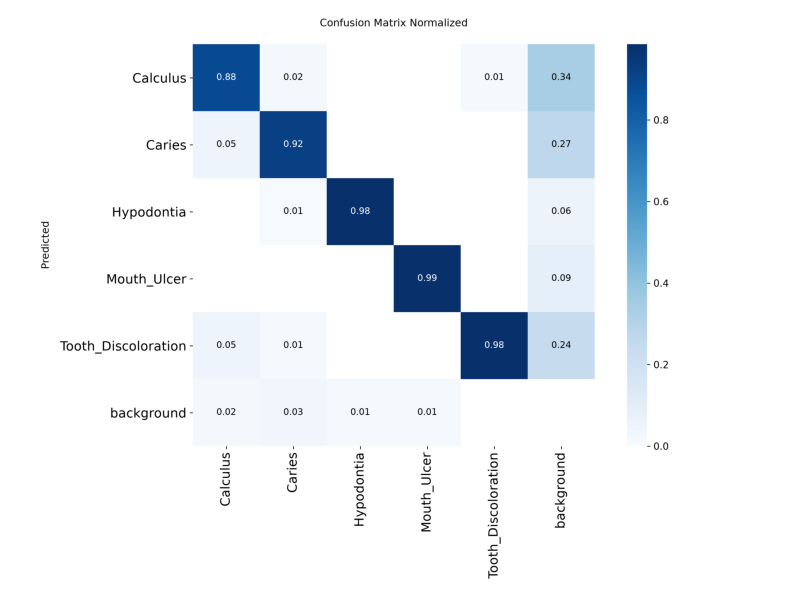

In [4]:
matrix = plt.imread(RUNS / "yolo11n_640_100ep_test" / "confusion_matrix_normalized.png")
plt.figure(figsize=(10, 7.5))
plt.imshow(matrix)
plt.axis("off")
plt.show()

**Finding:**

- When the model finds a box, it usually names it right: 92-99% for caries, hypodontia, ulcers and discolouration.
- **Calculus is the weak class** (test mAP50 0.628). 5% of calculus boxes are called caries and 5% discolouration, and calculus is the most common false alarm: 34% of the boxes drawn where nothing was labelled are calculus. Tartar and stains look alike in a photo.
- **The matrix keeps even very low-confidence boxes.** That is why almost nothing is missed here (bottom row 1-3% per class) and the false-alarm column is huge (the raw `confusion_matrix.png` shows 34,401 extra calculus boxes). At the balanced cut-off in the results table, recall is 0.76. What a user sees depends on the confidence cut-off the app uses.

**What I would do next:** pick the app's confidence cut-off on a held-out part of the data to trade false alarms against misses; check the calculus and discolouration labels; score on Aiden's clean test set, which has no copies of training photos.